In [36]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print(df.shape)
df.info()

(201, 29)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    object 
 3   aspiration         201 non-null    object 
 4   num-of-doors       201 non-null    object 
 5   body-style         201 non-null    object 
 6   drive-wheels       201 non-null    object 
 7   engine-location    201 non-null    object 
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    object 
 14  num-of-cylinders   201 non-null    object 
 15  engine-size        201 non-null    int64  
 16  fuel-system     

In [35]:
import pandas as pd

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/Data%20files/automobileEDA.csv"
df = pd.read_csv(url)
df.to_csv("automobileEDA.csv", index=False)   # saves a copy next to your notebook
df.head()


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


In [37]:
# count blanks and any "?" placeholders
print(df.isnull().sum()[df.isnull().sum() > 0])
print("Cells containing '?':", (df == "?").sum().sum())

stroke               4
horsepower-binned    1
dtype: int64
Cells containing '?': 0


In [38]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

Duplicate rows: 0


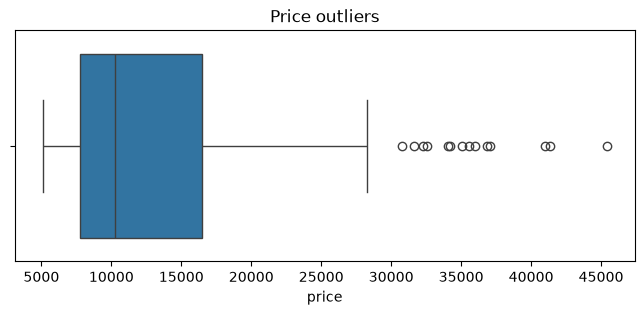

Price outliers: 14 | bounds: -5312 to 29588


In [39]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["price"])
plt.title("Price outliers")
plt.show()

q1, q3 = df["price"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df["price"] < low) | (df["price"] > high)]
print("Price outliers:", len(outliers), "| bounds:", round(low), "to", round(high))

In [40]:
# cap extreme prices at the bounds (keeps all rows, limits their influence)
df["price"] = df["price"].clip(low, high)

# fill any remaining gaps: median for numbers, most common value for text
num_cols = df.select_dtypes("number").columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
for c in df.select_dtypes("object").columns:
    df[c] = df[c].fillna(df[c].mode()[0])

print(df.isnull().sum().sum(), "missing values left | shape:", df.shape)

df.to_csv("YourLastName.Data.csv", index=False)   # replace YourLastName

0 missing values left | shape: (201, 29)


In [41]:
df.to_csv("Lawrence.Data.csv", index=False)

Data cleaning summary:** The dataset has 201 rows and 29 columns. Missing values were found in `stroke` (4) and `horsepower-binned` (1); numeric gaps were filled with the median and categorical gaps with the mode. No duplicate rows and no "?" placeholders were found. Using the IQR method (Q1 ≈ 7,775, Q3 ≈ 16,500, bounds −5,312 to 29,588), 14 high-price outliers were detected and capped at the upper bound to reduce their influence while keeping all records. The cleaned dataset was saved as Lawrence.Data.csv.

In [42]:
continuous = ["normalized-losses", "wheel-base", "length", "width", "height",
              "curb-weight", "engine-size", "bore", "stroke", "compression-ratio",
              "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "city-L/100km", "price"]

categorical = ["make", "aspiration", "num-of-doors", "body-style", "drive-wheels",
               "engine-location", "engine-type", "num-of-cylinders", "fuel-system",
               "horsepower-binned", "symboling"]

In [43]:
summary = df[continuous].describe().T
summary["skew"] = df[continuous].skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
normalized-losses,201.0,122.00,32.00,65.00,101.00,122.00,137.00,256.00,0.85
wheel-base,201.0,98.80,6.07,86.60,94.50,97.00,102.40,120.90,1.03
length,201.0,0.84,0.06,0.68,0.80,0.83,0.88,1.00,0.15
width,201.0,0.92,0.03,0.84,0.89,0.91,0.92,1.00,0.88
height,201.0,53.77,2.45,47.80,52.00,54.10,55.50,59.80,0.03
curb-weight,201.0,2555.67,517.30,1488.00,2169.00,2414.00,2926.00,4066.00,0.71
engine-size,201.0,126.88,41.55,61.00,98.00,120.00,141.00,326.00,1.98
bore,201.0,3.33,0.27,2.54,3.15,3.31,3.58,3.94,-0.03
stroke,201.0,3.26,0.32,2.07,3.11,3.29,3.41,4.17,-0.71
compression-ratio,201.0,10.16,4.00,7.00,8.60,9.00,9.40,23.00,2.58


In [44]:
for c in categorical:
    print(f"--- {c} ---")
    print(df[c].value_counts())
    print()

--- make ---
make
toyota           32
nissan           18
mazda            17
mitsubishi       13
honda            13
subaru           12
volkswagen       12
volvo            11
peugot           11
dodge             9
mercedes-benz     8
bmw               8
plymouth          7
audi              6
saab              6
porsche           4
chevrolet         3
alfa-romero       3
jaguar            3
isuzu             2
renault           2
mercury           1
Name: count, dtype: int64

--- aspiration ---
aspiration
std      165
turbo     36
Name: count, dtype: int64

--- num-of-doors ---
num-of-doors
four    115
two      86
Name: count, dtype: int64

--- body-style ---
body-style
sedan          94
hatchback      68
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64

--- drive-wheels ---
drive-wheels
fwd    118
rwd     75
4wd      8
Name: count, dtype: int64

--- engine-location ---
engine-location
front    198
rear       3
Name: count, dtype: int64

--- engine-ty

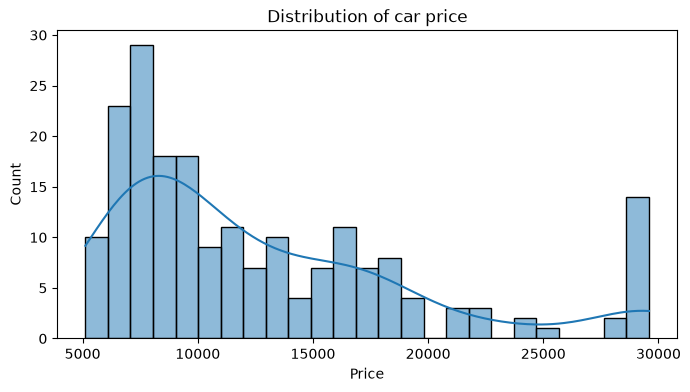

Mean: 12763 | Median: 10295


In [45]:
plt.figure(figsize=(8, 4))
sns.histplot(df["price"], bins=25, kde=True)
plt.title("Distribution of car price")
plt.xlabel("Price")
plt.show()

print("Mean:", round(df["price"].mean()), "| Median:", round(df["price"].median()))

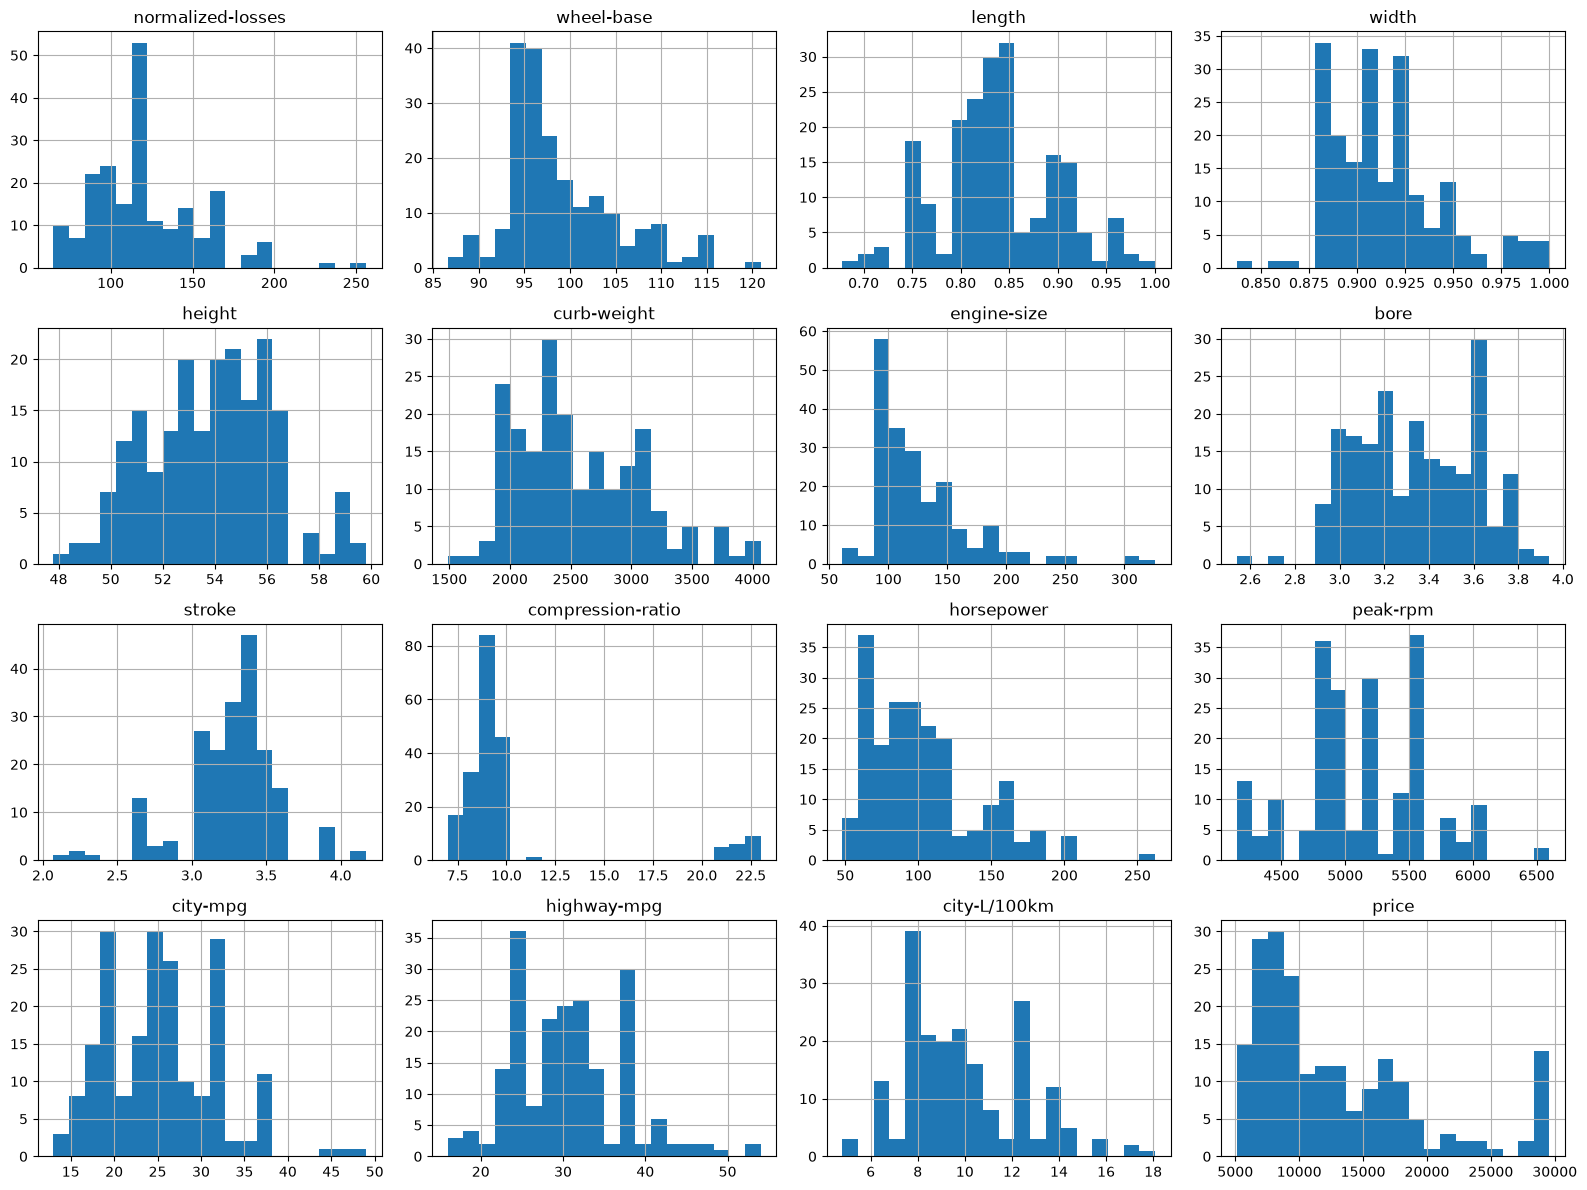

In [46]:
df[continuous].hist(bins=20, figsize=(16, 12))
plt.tight_layout()
plt.show()

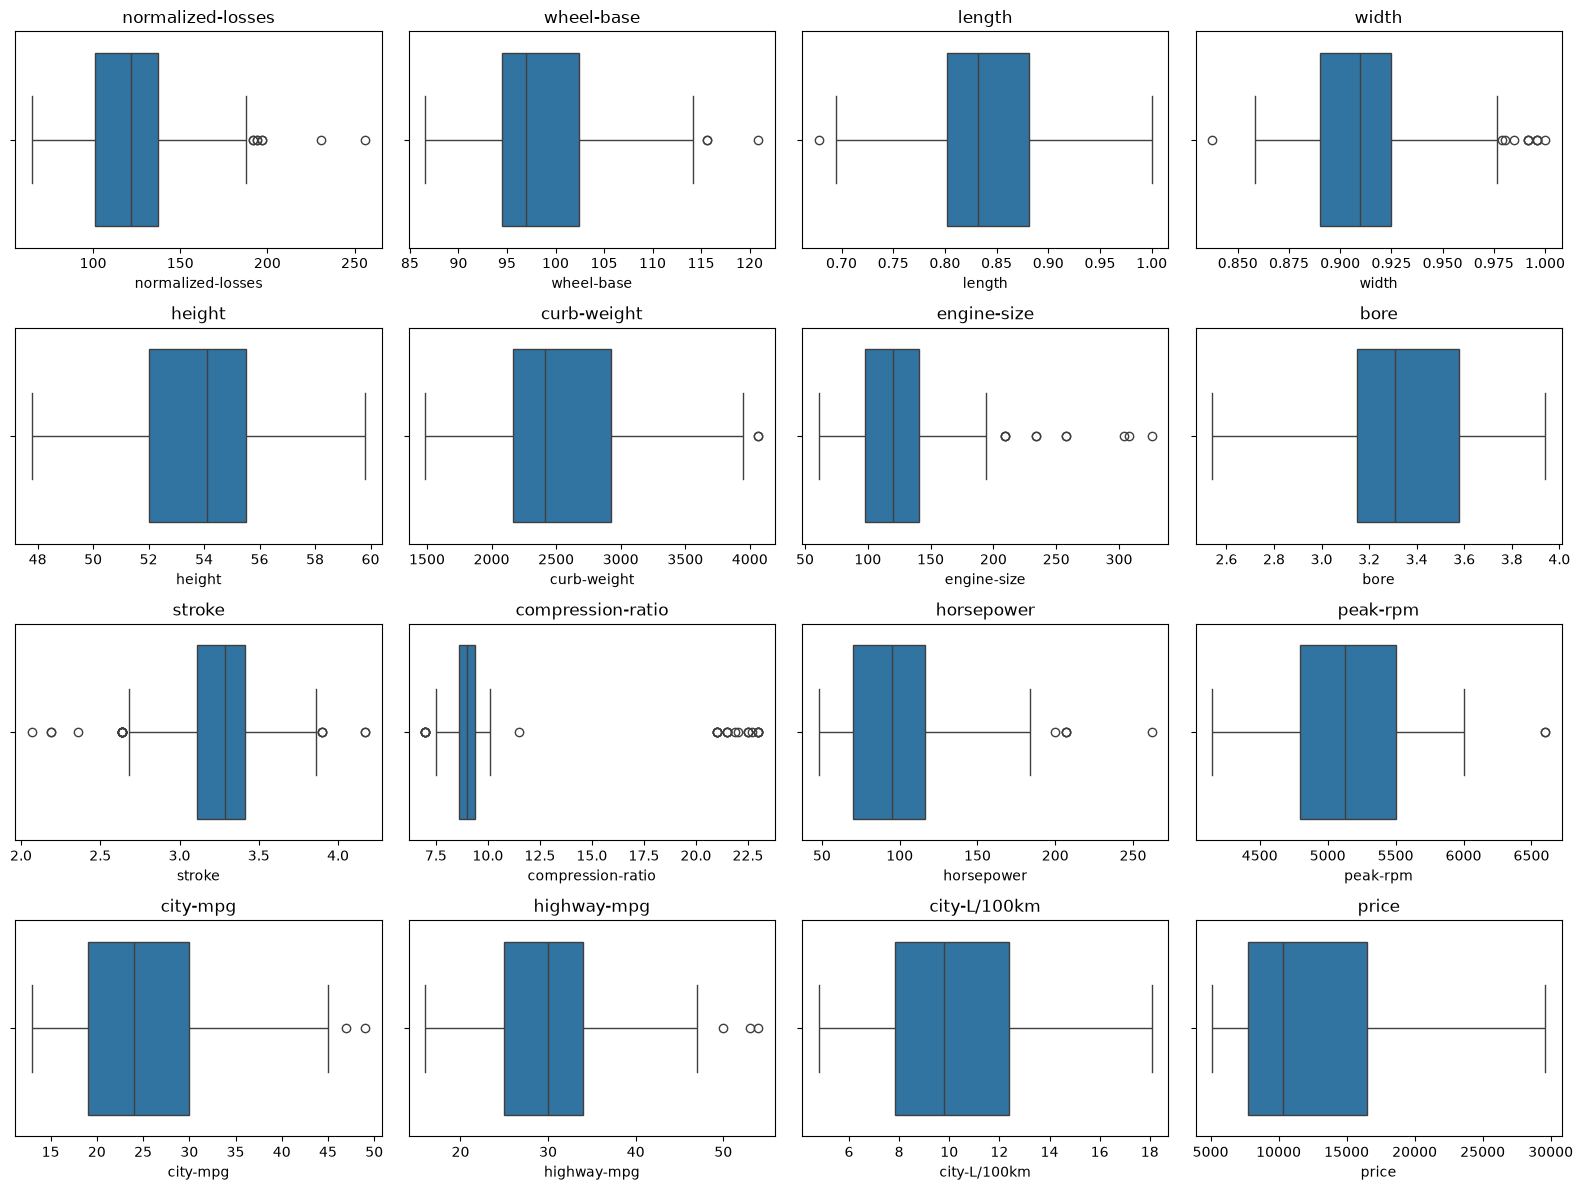

In [47]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, c in zip(axes.flatten(), continuous):
    sns.boxplot(x=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

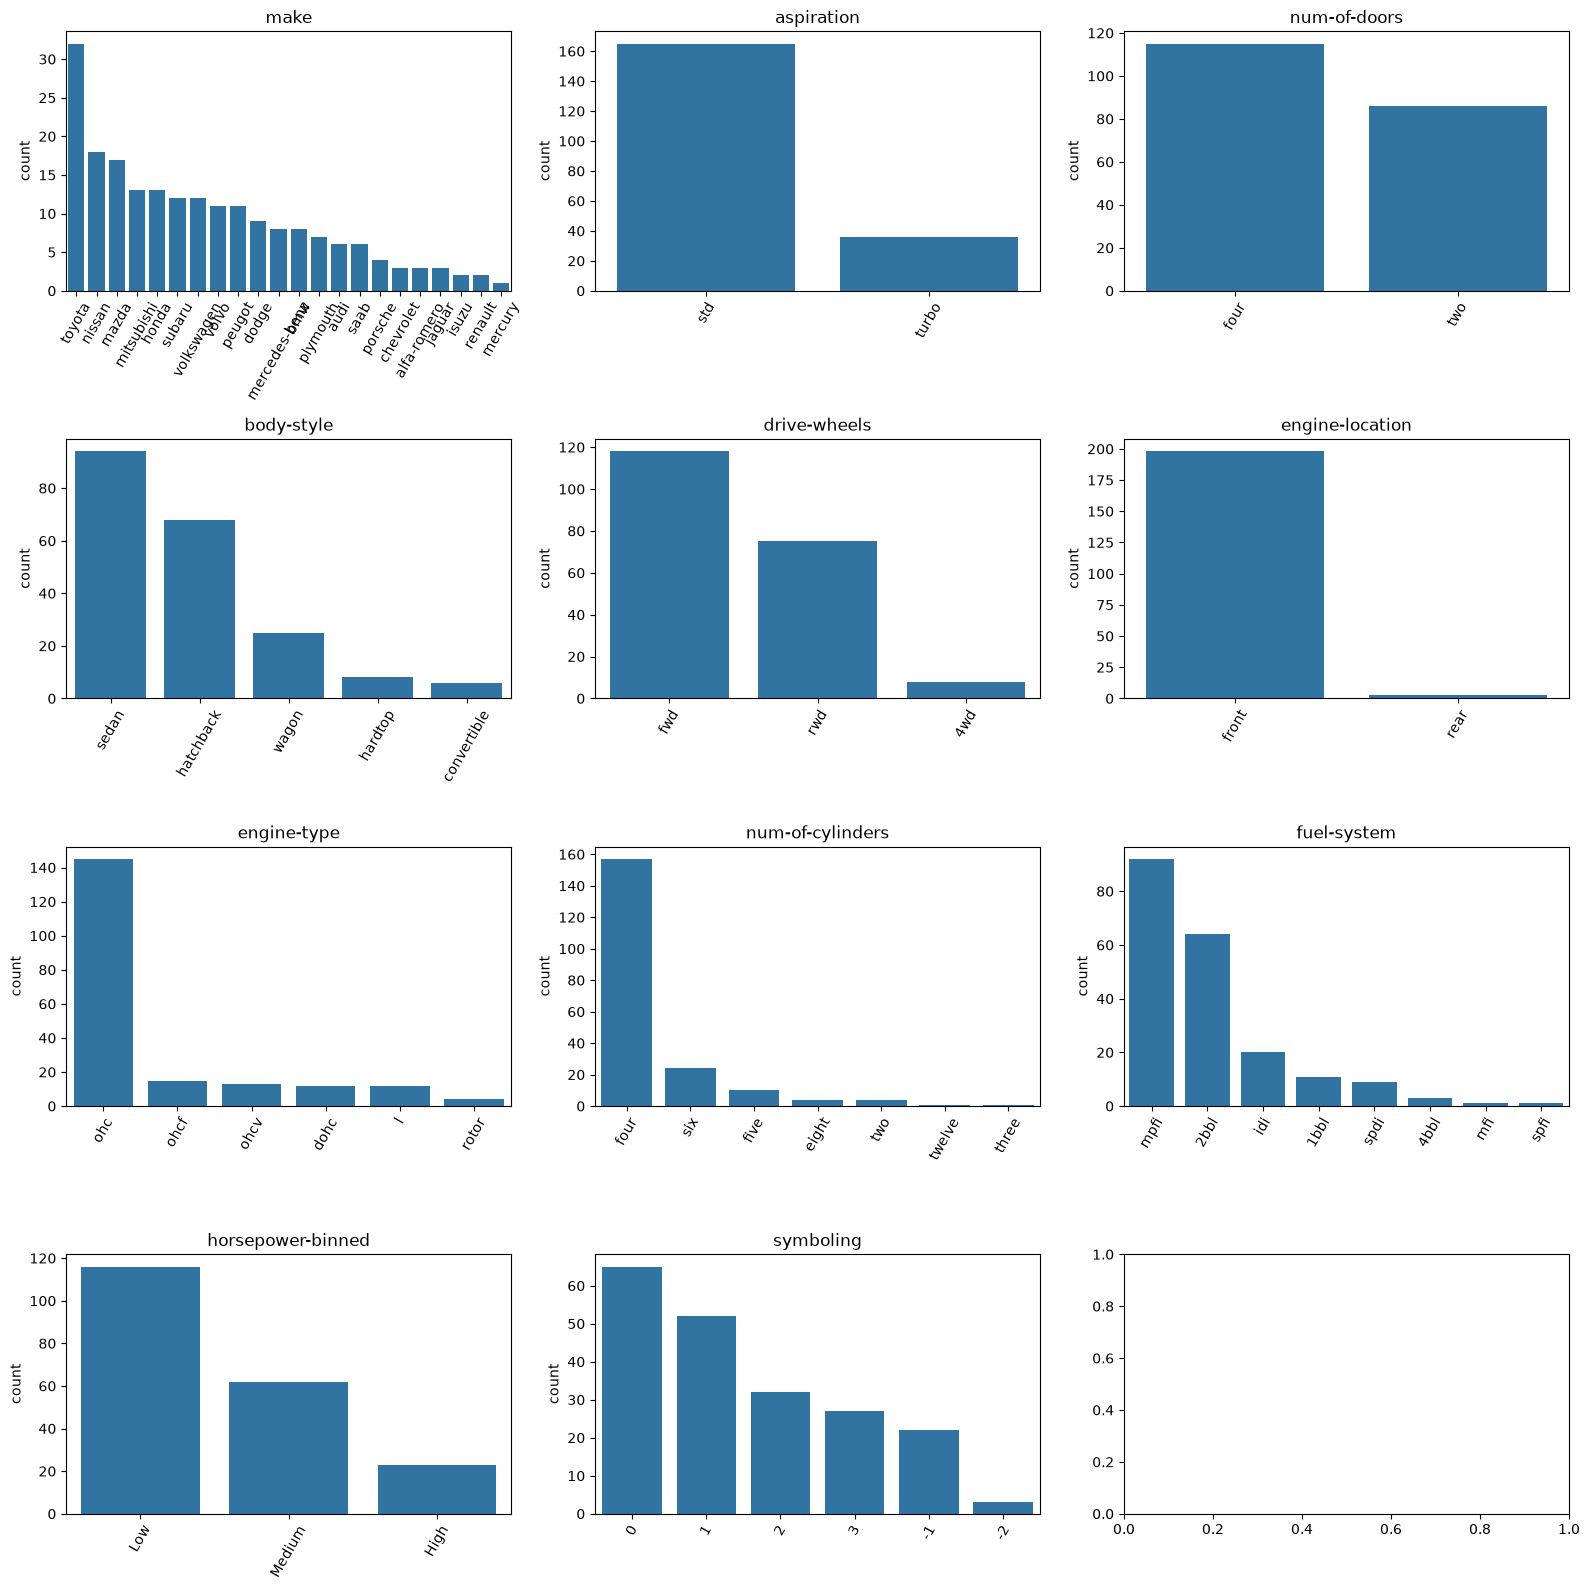

In [48]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
for ax, c in zip(axes.flatten(), categorical):
    order = df[c].value_counts().index
    sns.countplot(x=df[c], order=order, ax=ax)
    ax.set_title(c)
    ax.tick_params(axis="x", rotation=60)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Q2 Summary: Price ranges from 5,118 to 29,588 with a mean of 12,763 and a median of 10,295. The mean exceeding the median and a skewness of 1.23 show that price is right-skewed: most cars are low to mid-priced, with a few expensive ones. The spike at about 29,500 in the histogram is caused by capping the 14 outliers in Q1. Engine-size (1.98), compression-ratio (2.58) and horsepower (1.15) are also strongly right-skewed, while height, bore, length and peak-rpm are roughly symmetric. Among categorical variables, most cars have standard aspiration, and almost all have the engine at the front, so these carry little variation. The most common body style is sedan (94 of 201 cars), followed by hatchback (68), and the most common drive type is front-wheel drive (118 cars), followed by rear-wheel drive (75). The most common makes are Toyota (32 cars), Nissan (18) and Mazda (17). Larger engines and higher horsepower appear alongside higher prices, which is tested in Q4.

In [49]:
for col in ["drive-wheels", "body-style"]:
    print(f"--- {col} ---")
    print(df.groupby(col)["price"].agg(["count", "mean", "median"]).round(0).sort_values("mean"))
    print()

--- drive-wheels ---
              count     mean   median
drive-wheels                         
fwd             118   9245.0   8192.0
4wd               8  10241.0   9006.0
rwd              75  18567.0  16900.0

--- body-style ---
             count     mean   median
body-style                          
hatchback       68   9957.0   8672.0
wagon           25  12372.0  11694.0
sedan           94  13894.0  11078.0
hardtop          8  19309.0  19688.0
convertible      6  19739.0  17084.0



In [50]:
grouped = (df.groupby(["drive-wheels", "body-style"])["price"]
             .agg(["count", "mean", "median"])
             .round(0)
             .reset_index()
             .sort_values("mean", ascending=False))
grouped

,drive-wheels,body-style,count,mean,median
8,rwd,convertible,5,21368.0,17669.0
9,rwd,hardtop,7,20889.0,28176.0
11,rwd,sedan,36,20234.0,18382.0
12,rwd,wagon,9,16994.0,16515.0
10,rwd,hatchback,18,14338.0,14645.0
1,4wd,sedan,3,12647.0,11259.0
3,fwd,convertible,1,11595.0,11595.0
7,fwd,wagon,12,9997.0,8921.0
6,fwd,sedan,55,9812.0,8558.0
2,4wd,wagon,4,9096.0,8396.0


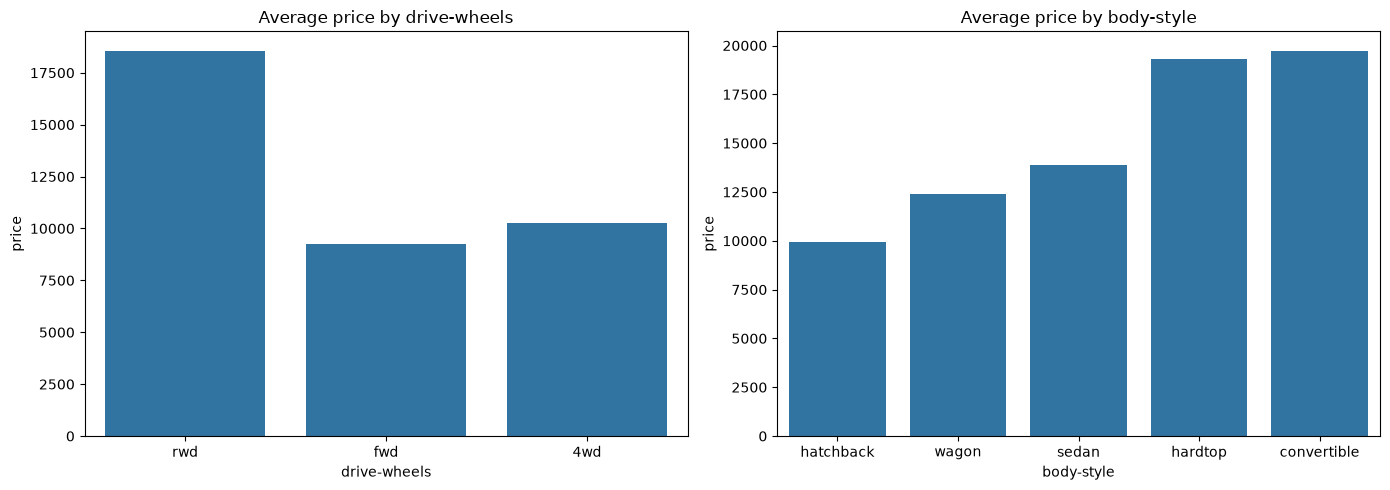

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x="drive-wheels", y="price", data=df, estimator="mean", errorbar=None, ax=axes[0])
axes[0].set_title("Average price by drive-wheels")

order = df.groupby("body-style")["price"].mean().sort_values().index
sns.barplot(x="body-style", y="price", data=df, estimator="mean", errorbar=None, order=order, ax=axes[1])
axes[1].set_title("Average price by body-style")

plt.tight_layout()
plt.show()

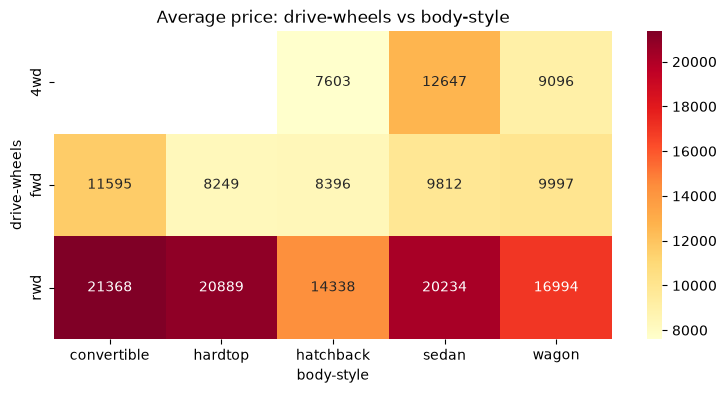

In [52]:
pivot = df.pivot_table(values="price", index="drive-wheels", columns="body-style", aggfunc="mean")

plt.figure(figsize=(9, 4))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("Average price: drive-wheels vs body-style")
plt.show()

In [53]:
top = grouped.iloc[0]
bottom = grouped.iloc[-1]
print("HIGHEST:", top["drive-wheels"], "+", top["body-style"], "| avg price:", top["mean"], "| cars:", top["count"])
print("LOWEST: ", bottom["drive-wheels"], "+", bottom["body-style"], "| avg price:", bottom["mean"], "| cars:", bottom["count"])

HIGHEST: rwd + convertible | avg price: 21368.0 | cars: 5
LOWEST:  4wd + hatchback | avg price: 7603.0 | cars: 1


Q3 Summary: Cars were grouped by drive-wheels and body-style. By drive type, rear-wheel drive (rwd) cars are by far the most expensive on average (about 18,570), while front-wheel drive (fwd, about 9,240) and four-wheel drive (4wd, about 10,240) are much cheaper. By body style, convertibles (about 19,740) and hardtops (about 19,310) are the most expensive and hatchbacks (about 9,960) the cheapest. Combining both parameters, the highest-priced group is rwd convertible (average 21,368, n = 5) and the lowest is 4wd hatchback (average 7,603, n = 1). Since the lowest group has only one car, the more reliable extremes among larger groups are rwd sedan (20,234, n = 36) as the most expensive and fwd hatchback (8,396, n = 49) as the cheapest. In every body style, rwd cars cost more than fwd cars, so drive type appears strongly linked to price. Note that prices above 29,588 were capped in Q1, so averages for the most expensive groups may be slightly understated.

highway-mpg         -0.73
city-mpg            -0.72
peak-rpm            -0.11
stroke               0.09
compression-ratio    0.11
normalized-losses    0.16
height               0.16
bore                 0.56
wheel-base           0.61
length               0.72
width                0.78
city-L/100km         0.80
horsepower           0.82
engine-size          0.84
curb-weight          0.86
Name: price, dtype: float64


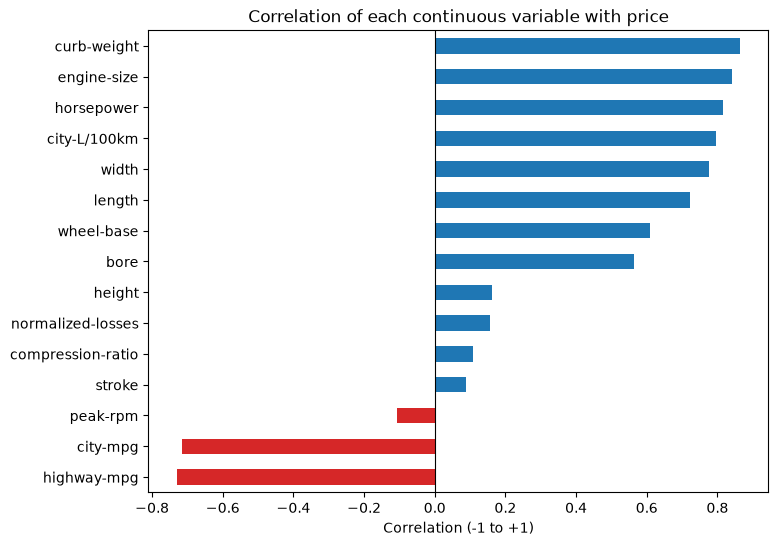

In [54]:
corr = df[continuous].corr()["price"].drop("price").sort_values()
print(corr.round(2))

plt.figure(figsize=(8, 6))
corr.plot(kind="barh", color=["tab:red" if v < 0 else "tab:blue" for v in corr])
plt.title("Correlation of each continuous variable with price")
plt.xlabel("Correlation (-1 to +1)")
plt.axvline(0, color="black", lw=0.8)
plt.show()

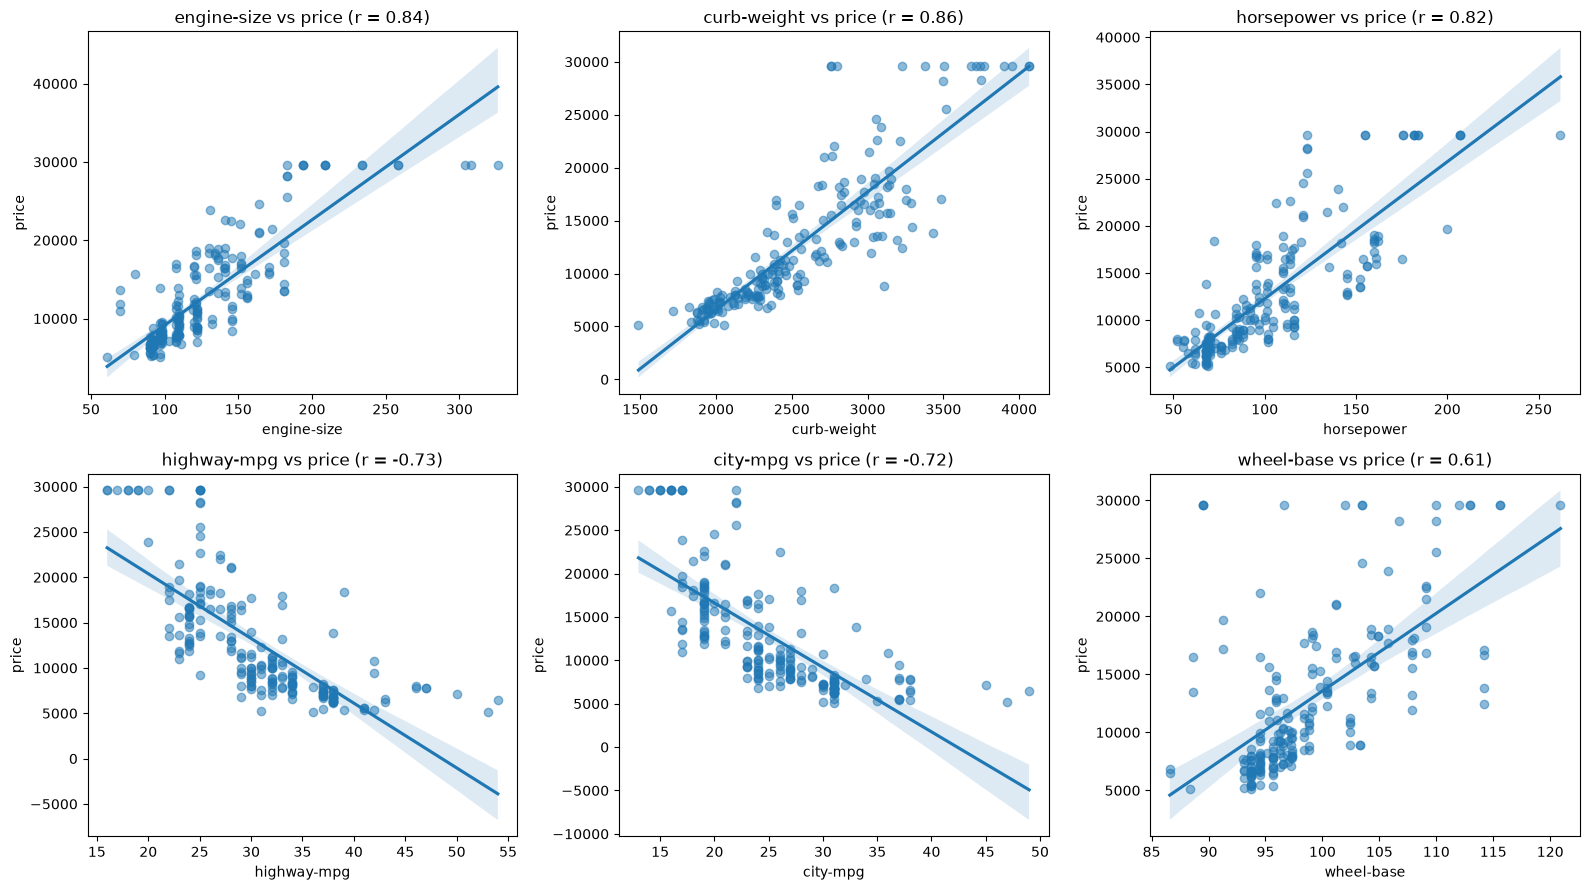

In [55]:
top_vars = ["engine-size", "curb-weight", "horsepower", "highway-mpg", "city-mpg", "wheel-base"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.flatten(), top_vars):
    sns.regplot(x=c, y="price", data=df, ax=ax, scatter_kws={"alpha": 0.5})
    ax.set_title(f"{c} vs price (r = {df[c].corr(df['price']):.2f})")
plt.tight_layout()
plt.show()

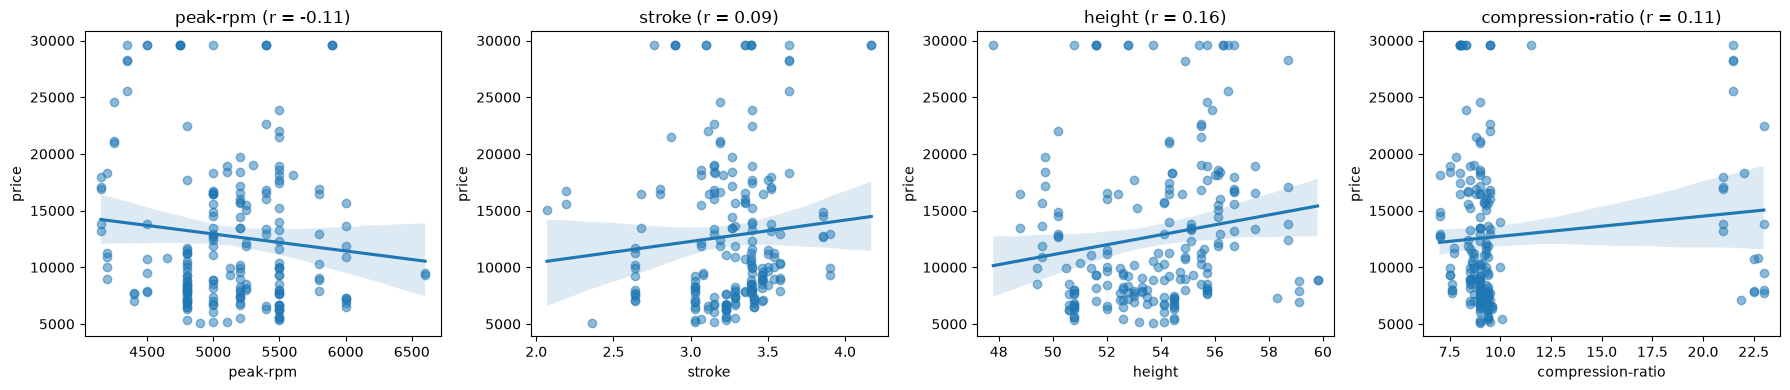

In [56]:
weak_vars = ["peak-rpm", "stroke", "height", "compression-ratio"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, weak_vars):
    sns.regplot(x=c, y="price", data=df, ax=ax, scatter_kws={"alpha": 0.5})
    ax.set_title(f"{c} (r = {df[c].corr(df['price']):.2f})")
plt.tight_layout()
plt.show()

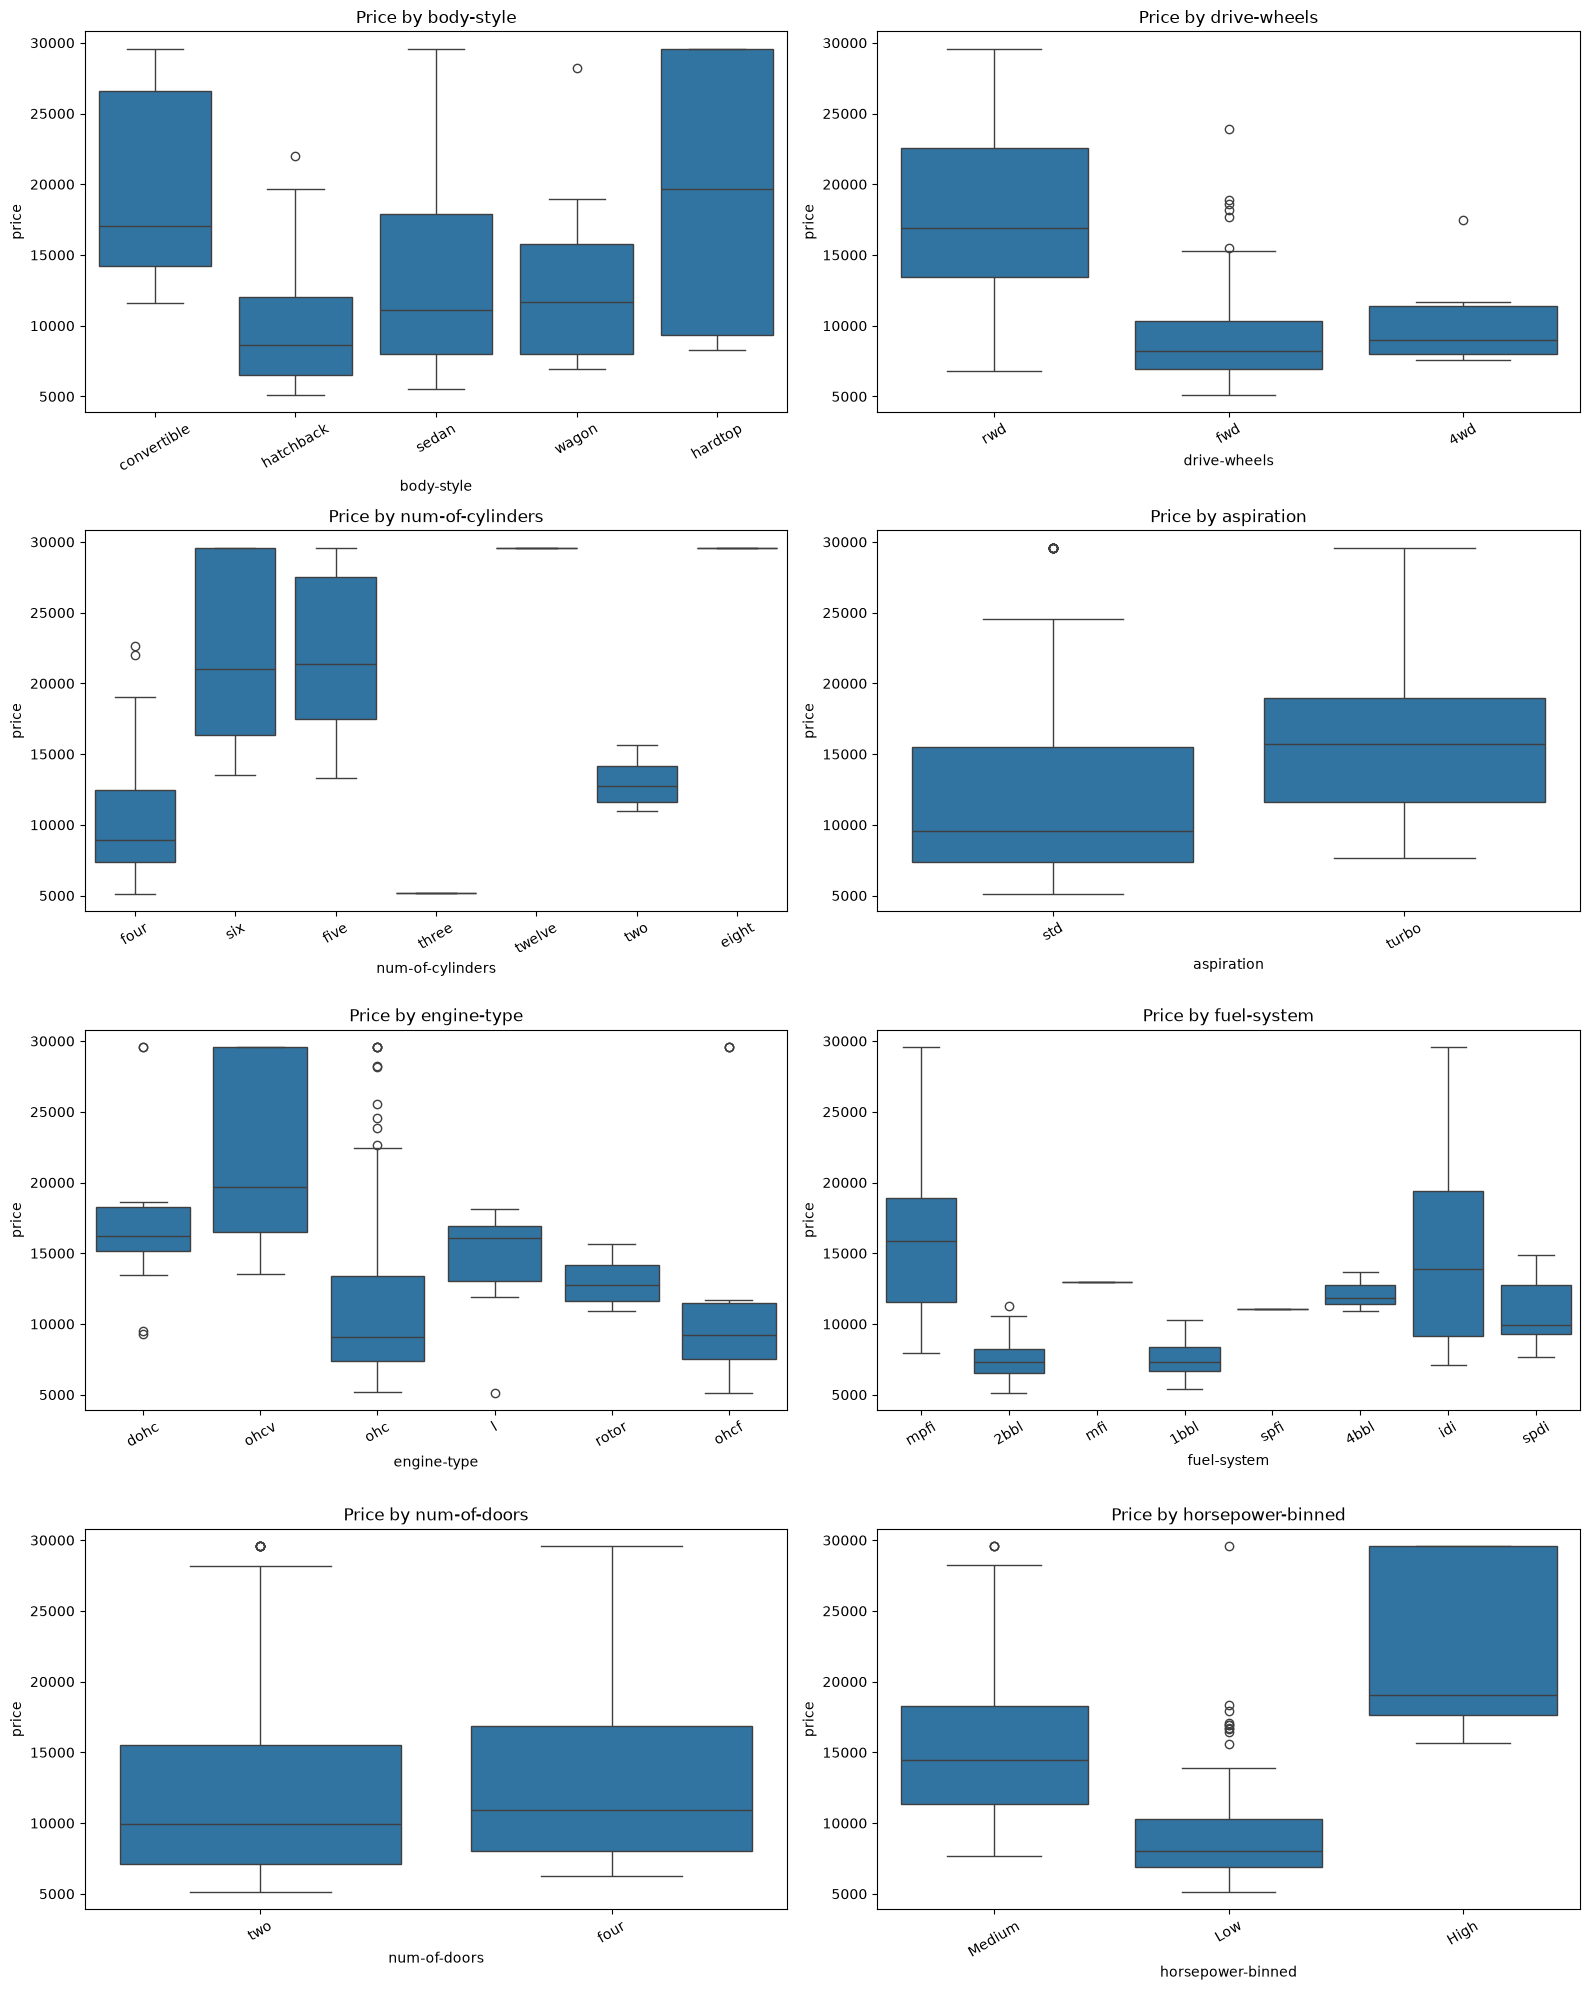

In [57]:
cat_vars = ["body-style", "drive-wheels", "num-of-cylinders", "aspiration",
            "engine-type", "fuel-system", "num-of-doors", "horsepower-binned"]

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
for ax, c in zip(axes.flatten(), cat_vars):
    sns.boxplot(x=c, y="price", data=df, ax=ax)
    ax.set_title(f"Price by {c}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

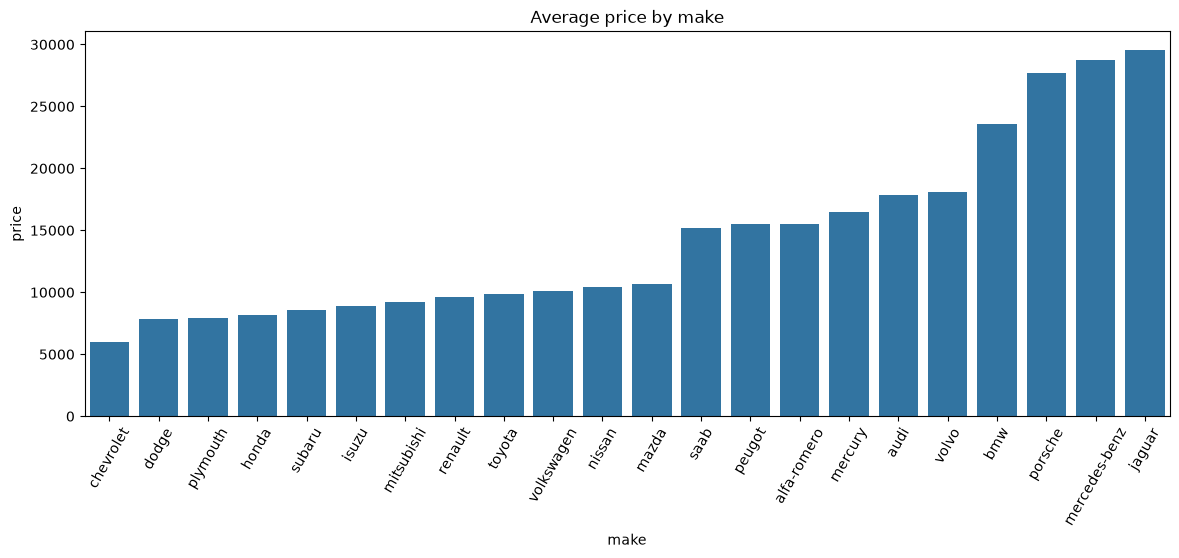

In [58]:
order = df.groupby("make")["price"].mean().sort_values().index
plt.figure(figsize=(14, 5))
sns.barplot(x="make", y="price", data=df, order=order, errorbar=None)
plt.xticks(rotation=60)
plt.title("Average price by make")
plt.show()

In [59]:
for c in cat_vars + ["make"]:
    group_means = df.groupby(c)["price"].mean()
    print(f"{c:20s} gap between cheapest and priciest group: {group_means.max() - group_means.min():,.0f}")

body-style           gap between cheapest and priciest group: 9,782
drive-wheels         gap between cheapest and priciest group: 9,322
num-of-cylinders     gap between cheapest and priciest group: 24,436
aspiration           gap between cheapest and priciest group: 4,186
engine-type          gap between cheapest and priciest group: 10,326
fuel-system          gap between cheapest and priciest group: 9,223
num-of-doors         gap between cheapest and priciest group: 1,006
horsepower-binned    gap between cheapest and priciest group: 13,631
make                 gap between cheapest and priciest group: 23,580


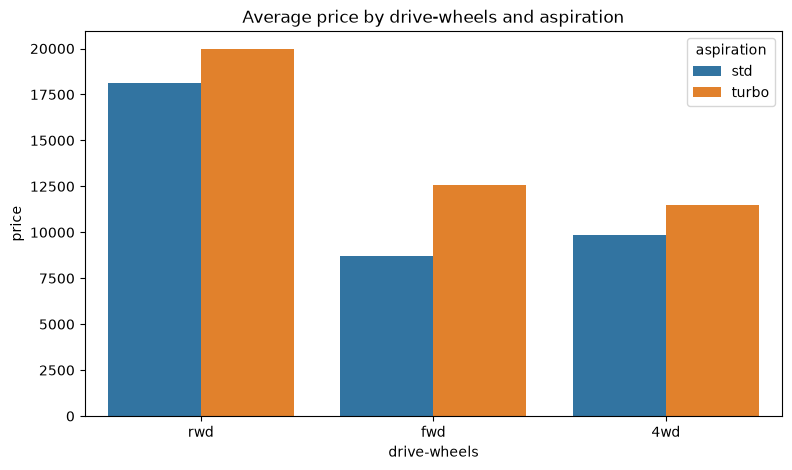

aspiration        std    turbo
drive-wheels                  
4wd            9829.0  11476.0
fwd            8724.0  12565.0
rwd           18129.0  19954.0

aspiration    std  turbo
drive-wheels            
4wd             6      2
fwd           102     16
rwd            57     18


In [60]:
plt.figure(figsize=(9, 5))
sns.barplot(x="drive-wheels", y="price", hue="aspiration", data=df, errorbar=None)
plt.title("Average price by drive-wheels and aspiration")
plt.show()

pivot = df.pivot_table(values="price", index="drive-wheels", columns="aspiration", aggfunc="mean")
counts = df.pivot_table(values="price", index="drive-wheels", columns="aspiration", aggfunc="count")
print(pivot.round(0))
print()
print(counts)

Q4 (a) Continuous variables vs price: Curb-weight (r = 0.86), engine-size (0.84), horsepower (0.82), city-L/100km (0.80, thirstier cars cost more), width (0.78) and length (0.72) have strong positive relationships with price: larger, heavier, more powerful cars cost more. Highway-mpg (−0.73) and city-mpg (−0.72) have strong negative relationships: fuel-efficient cars are cheaper. Wheel-base (0.61) and bore (0.56) are moderate. Peak-rpm (−0.11), stroke (0.09), compression-ratio (0.11), height (0.16) and normalized-losses (0.16) are weak, and their scatter plots show no clear trend. Many of the strong variables also correlate with each other (a heavier car usually has a bigger engine), so they overlap in what they tell us.

Q4 (b) Categorical variables vs price: The price gap between the cheapest and most expensive category is largest for num-of-cylinders (24,436) and make (23,580), followed by horsepower-binned (13,631), engine-type (10,326), body-style (9,782), drive-wheels (9,322) and fuel-system (9,223). The cylinders gap is misleading, because it compares two groups with one car each (twelve cylinders and three cylinders); most cars have four cylinders (157 of 201), followed by six (24) and five (10). Boxplots show clear separation for horsepower-binned (Low < Medium < High) and drive-wheels (rwd well above fwd and 4wd). Make shows a wide spread in average price. The most expensive makes are Jaguar (29,588), Mercedes-Benz (28,739), Porsche (27,695) and BMW (23,595), while the cheapest are Chevrolet (6,007), Dodge (7,875), Plymouth (7,963) and Honda (8,185). Toyota, the most common make with 32 cars, averages 9,886. Jaguar's average equals the cap applied in Q1, so its true average is higher, and Chevrolet, Jaguar and Porsche each have only 3 to 4 cars, so their averages are less reliable. Aspiration has a moderate effect (gap 4,186; turbo higher), and num-of-doors has almost none (gap 1,006, boxes overlap).

Q4 (c) Two categorical variables (drive-wheels and aspiration): Turbo cars cost more than standard cars in every drive type: 4wd 11,476 vs 9,829, fwd 12,565 vs 8,724, and rwd 19,954 vs 18,129. The turbo premium is largest for fwd (+3,841). However, drive type has the bigger effect: standard rwd cars (18,129) cost more than turbo fwd cars (12,565). Some combinations, such as 4wd turbo (2 cars), have very few cars, so those averages should be treated with caution.

In [61]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score, KFold

# drop two columns that are just re-expressions of other columns
data = df.drop(columns=["horsepower-binned", "city-L/100km"])

y = data["price"]
# turn text categories into 0/1 columns the model can use
X = pd.get_dummies(data.drop(columns="price"), prefix_sep="__", drop_first=True).astype(float)
print(X.shape)

(201, 65)


curb-weight          0.477
engine-size          0.323
highway-mpg          0.055
horsepower           0.045
width                0.019
city-mpg             0.018
make                 0.011
wheel-base           0.008
normalized-losses    0.007
length               0.006
dtype: float64


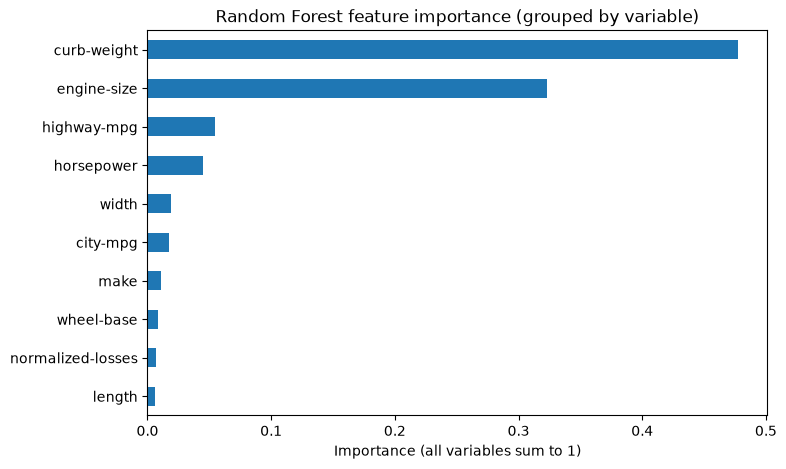

In [62]:
rf = RandomForestRegressor(n_estimators=300, random_state=42)
rf.fit(X, y)

imp = pd.Series(rf.feature_importances_, index=X.columns)
# add the yes/no pieces back together under their original variable name
grouped_imp = imp.groupby(lambda c: c.split("__")[0]).sum().sort_values(ascending=False)

print(grouped_imp.head(10).round(3))
grouped_imp.head(10).plot(kind="barh", figsize=(8, 5)).invert_yaxis()
plt.title("Random Forest feature importance (grouped by variable)")
plt.xlabel("Importance (all variables sum to 1)")
plt.show()

curb-weight    589.0
engine-size    477.3
horsepower     393.7
width          301.5
highway-mpg    227.8
length         217.3
city-mpg       209.5
wheel-base     118.0
bore            92.3
height           5.3
dtype: float64


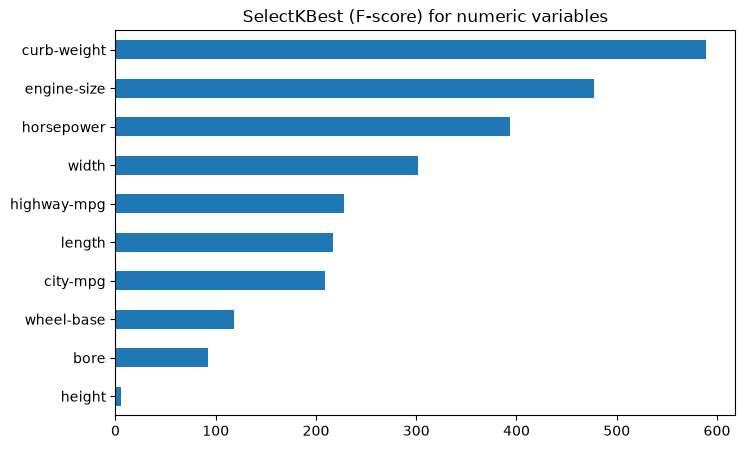

In [63]:
X_num = data.select_dtypes("number").drop(columns="price")

skb = SelectKBest(f_regression, k="all").fit(X_num, y)
scores = pd.Series(skb.scores_, index=X_num.columns).sort_values(ascending=False)

print(scores.head(10).round(1))
scores.head(10).plot(kind="barh", figsize=(8, 5)).invert_yaxis()
plt.title("SelectKBest (F-score) for numeric variables")
plt.show()

In [64]:
cv = KFold(5, shuffle=True, random_state=42)

top5 = list(grouped_imp.head(5).index)
X_top = pd.get_dummies(data[top5], prefix_sep="__", drop_first=True).astype(float)

r2_all = cross_val_score(RandomForestRegressor(n_estimators=300, random_state=42), X, y, cv=cv, scoring="r2").mean()
r2_top = cross_val_score(RandomForestRegressor(n_estimators=300, random_state=42), X_top, y, cv=cv, scoring="r2").mean()

print("Top 5 variables:", top5)
print(f"R² using all variables: {r2_all:.2f}")
print(f"R² using only top 5:    {r2_top:.2f}")

Top 5 variables: ['curb-weight', 'engine-size', 'highway-mpg', 'horsepower', 'width']
R² using all variables: 0.88
R² using only top 5:    0.89


Q5 Feature selection and recommendation:** To find the variables with the most impact on price, a Random Forest model was fitted on all variables, with categorical columns grouped back to their original names. It ranked these five variables highest, in order: curb-weight, engine-size, highway-mpg, horsepower and width. This agrees with the correlations in Q4 (curb-weight 0.86, engine-size 0.84, horsepower 0.82, width 0.78, highway-mpg −0.73). To test whether these five are enough, a model was cross-validated (5 folds) using only them. It reached R² = 0.89, compared with R² = 0.88 using all variables, so the five variables carry essentially all of the useful pricing information and the remaining variables add nothing. No categorical variable reached the top five. Make and drive-wheels showed clear price differences in Q4, but these differences are most likely already captured by the size, power and fuel-economy measurements. Variables with weak correlations in Q4, such as peak-rpm, stroke, compression-ratio, height and normalized-losses, contributed little. The top five overlap with each other, since a heavier car usually has a bigger, more powerful engine, so their exact order matters less than the fact that they form one group.

Recommendation for a car dealer: Price a car mainly by its size and power: curb-weight, engine-size and horsepower. These are the strongest signals, and a car with larger values in all three should be priced higher. Treat fuel economy as the opposite signal, because cars with higher highway-mpg are cheaper, so efficient small cars should be priced lower. Width is a further indicator of a bigger, more expensive car. Then adjust for drive type: standard rear-wheel-drive cars averaged 18,129 against 8,724 for standard front-wheel-drive cars, and turbo adds a premium in every drive type. Features such as number of doors had almost no effect on price and should not drive pricing decisions. These findings come from 201 cars, and prices above 29,588 were capped, so the premium for very high-end cars may be understated.